In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Import bf image

In [2]:
bf_matrix = np.genfromtxt('./data/csv/bf_matrix.csv', delimiter=',').reshape(1600,128)

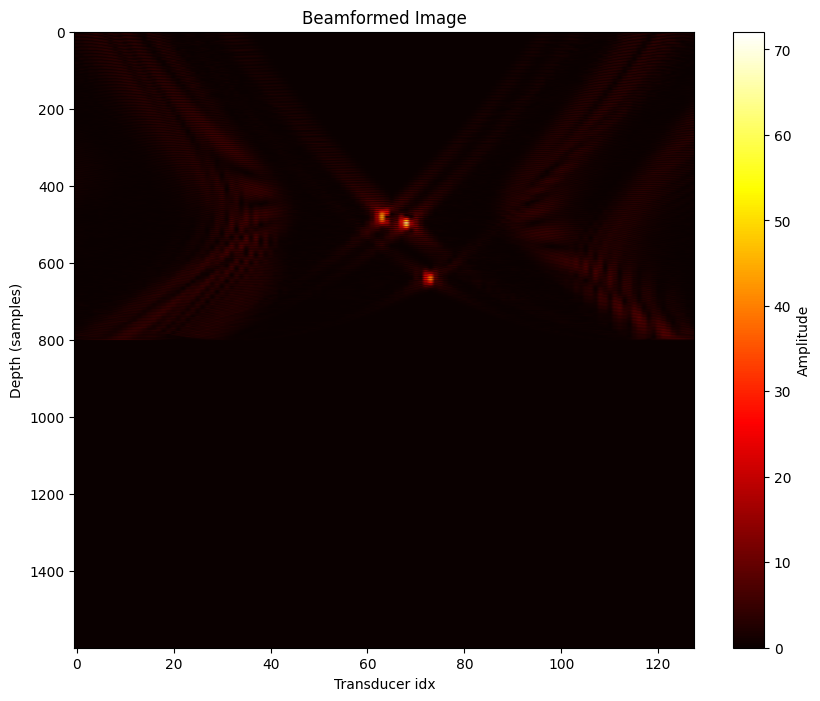

In [3]:
plt.figure(figsize=(10, 8))
plt.imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Transducer idx")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.savefig("./data/images/bf_image.png")
plt.show()

# Rescale image

C:\Users\Acer\AppData\Local\Temp\ipykernel_16188\1582008583.py:6: RuntimeWarning: divide by zero encountered in log10
  ax[1].imshow(np.log10(bf_matrix), cmap='cool', aspect='auto')
C:\Users\Acer\AppData\Local\Temp\ipykernel_16188\1582008583.py:6: RuntimeWarning: invalid value encountered in log10
  ax[1].imshow(np.log10(bf_matrix), cmap='cool', aspect='auto')


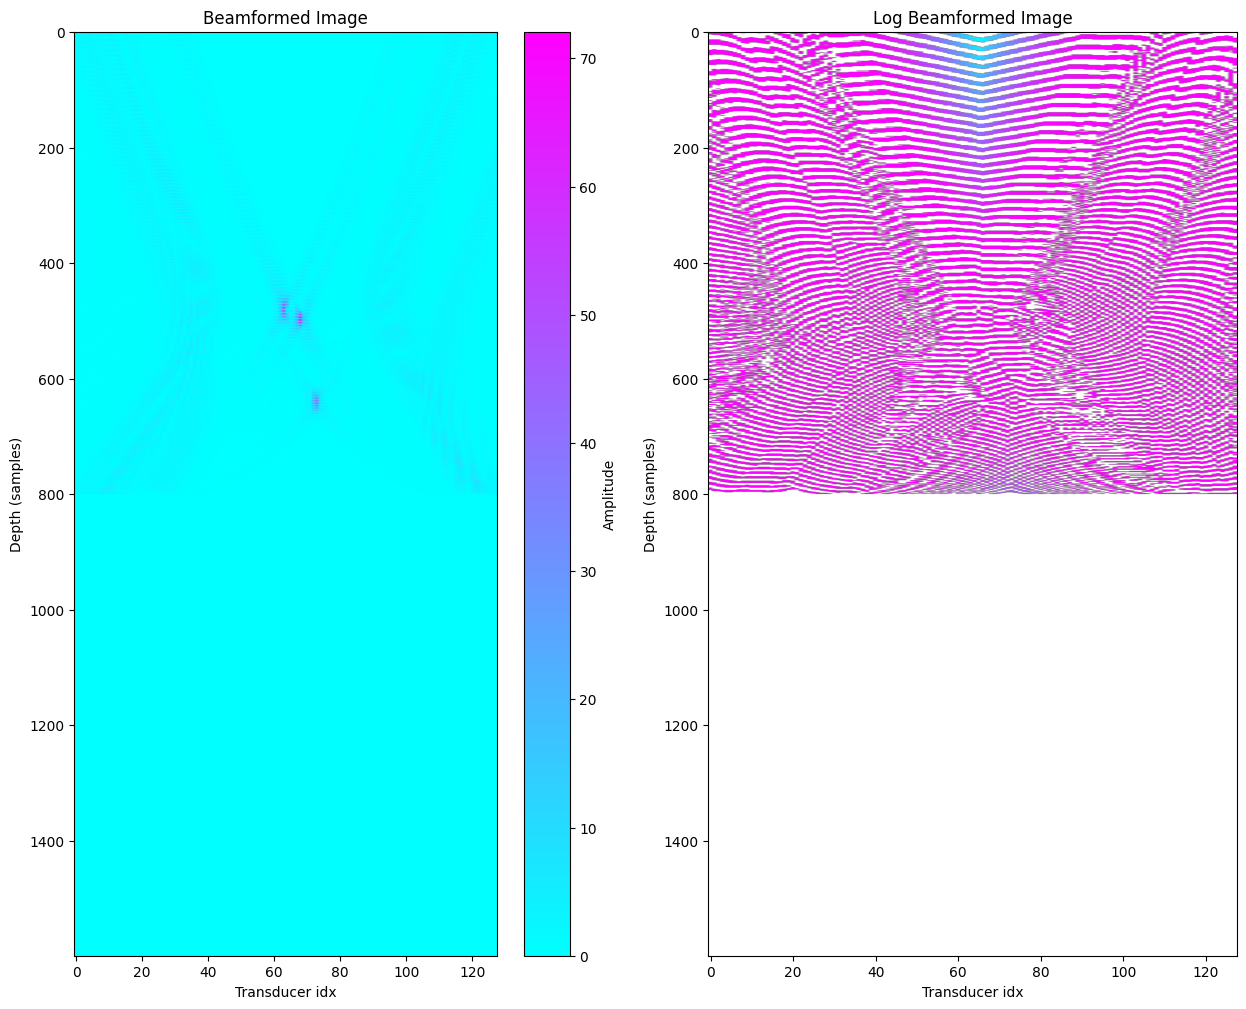

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(15, 12))
ax[0].imshow(np.abs(bf_matrix), cmap='hot', aspect='auto')
ax[0].set_title("Beamformed Image")
ax[0].set_xlabel("Transducer idx")
ax[0].set_ylabel("Depth (samples)")
ax[1].imshow(np.log10(bf_matrix), cmap='hot', aspect='auto')
ax[1].set_title("Log Beamformed Image") 
ax[1].set_xlabel("Transducer idx")
ax[1].set_ylabel("Depth (samples)")
fig.colorbar(label="Amplitude", mappable=ax[0].images[0])
plt.show()

In [10]:
#return the maximum value of the beamformed image
max_val = np.max(np.abs(bf_matrix))
print("Maximum value of the beamformed image: ", max_val)

Maximum value of the beamformed image:  72.07864985690577


# Get image zone

In [129]:
def extract_highest_value_region(bf_matrix, submatrix_size=100):
    row, col = np.unravel_index(np.argmax(bf_matrix), bf_matrix.shape)
    
    half_size = int(submatrix_size/2)
    row_start = row - half_size
    row_end = row + half_size
    col_start = col - half_size
    col_end = col + half_size

    return bf_matrix[row_start:row_end, col_start:col_end]

In [130]:
high_energy_zone = extract_highest_value_region(bf_matrix, submatrix_size=120)

# Visualize lobes

C:\Users\Acer\AppData\Local\Temp\ipykernel_16188\592822493.py:4: RuntimeWarning: invalid value encountered in log10
  ax[1].imshow(np.log10(high_energy_zone), cmap='hot')


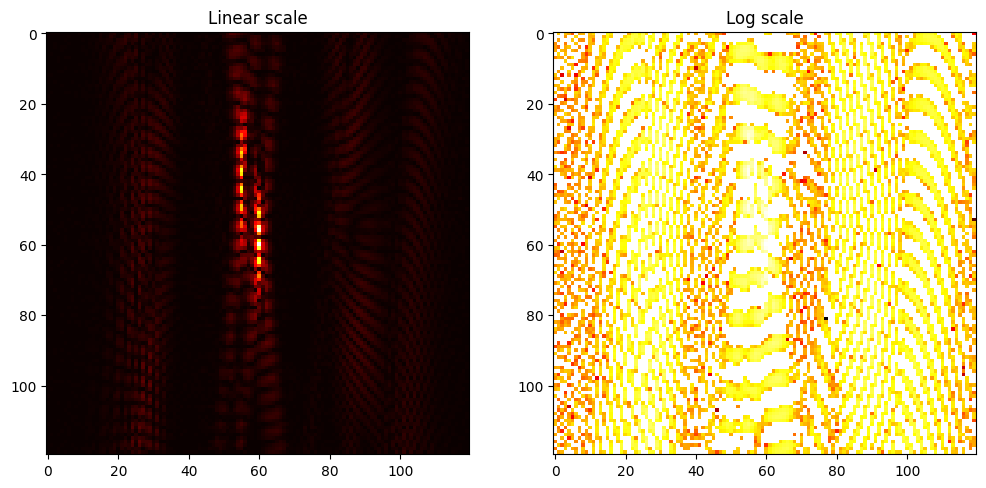

In [131]:
fig, ax = plt.subplots(1,2, figsize=(12, 10))
ax[0].imshow(np.abs(high_energy_zone), cmap='hot')
ax[0].set_title("Linear scale")
ax[1].imshow(np.log10(high_energy_zone), cmap='hot')
ax[1].set_title("Log scale")
plt.show()